In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import correlate

In [2]:
densityfname = "example_density_phases_dump.csv"
data = np.genfromtxt(densityfname, delimiter=",", names=True)
rho_all_dense = data["rho_dense_all"]
time = data["time"]

## Autocorrelation
Using scipy.signal.correlate to find the autocorrelation of dense phase density of all components in a sample simulation.

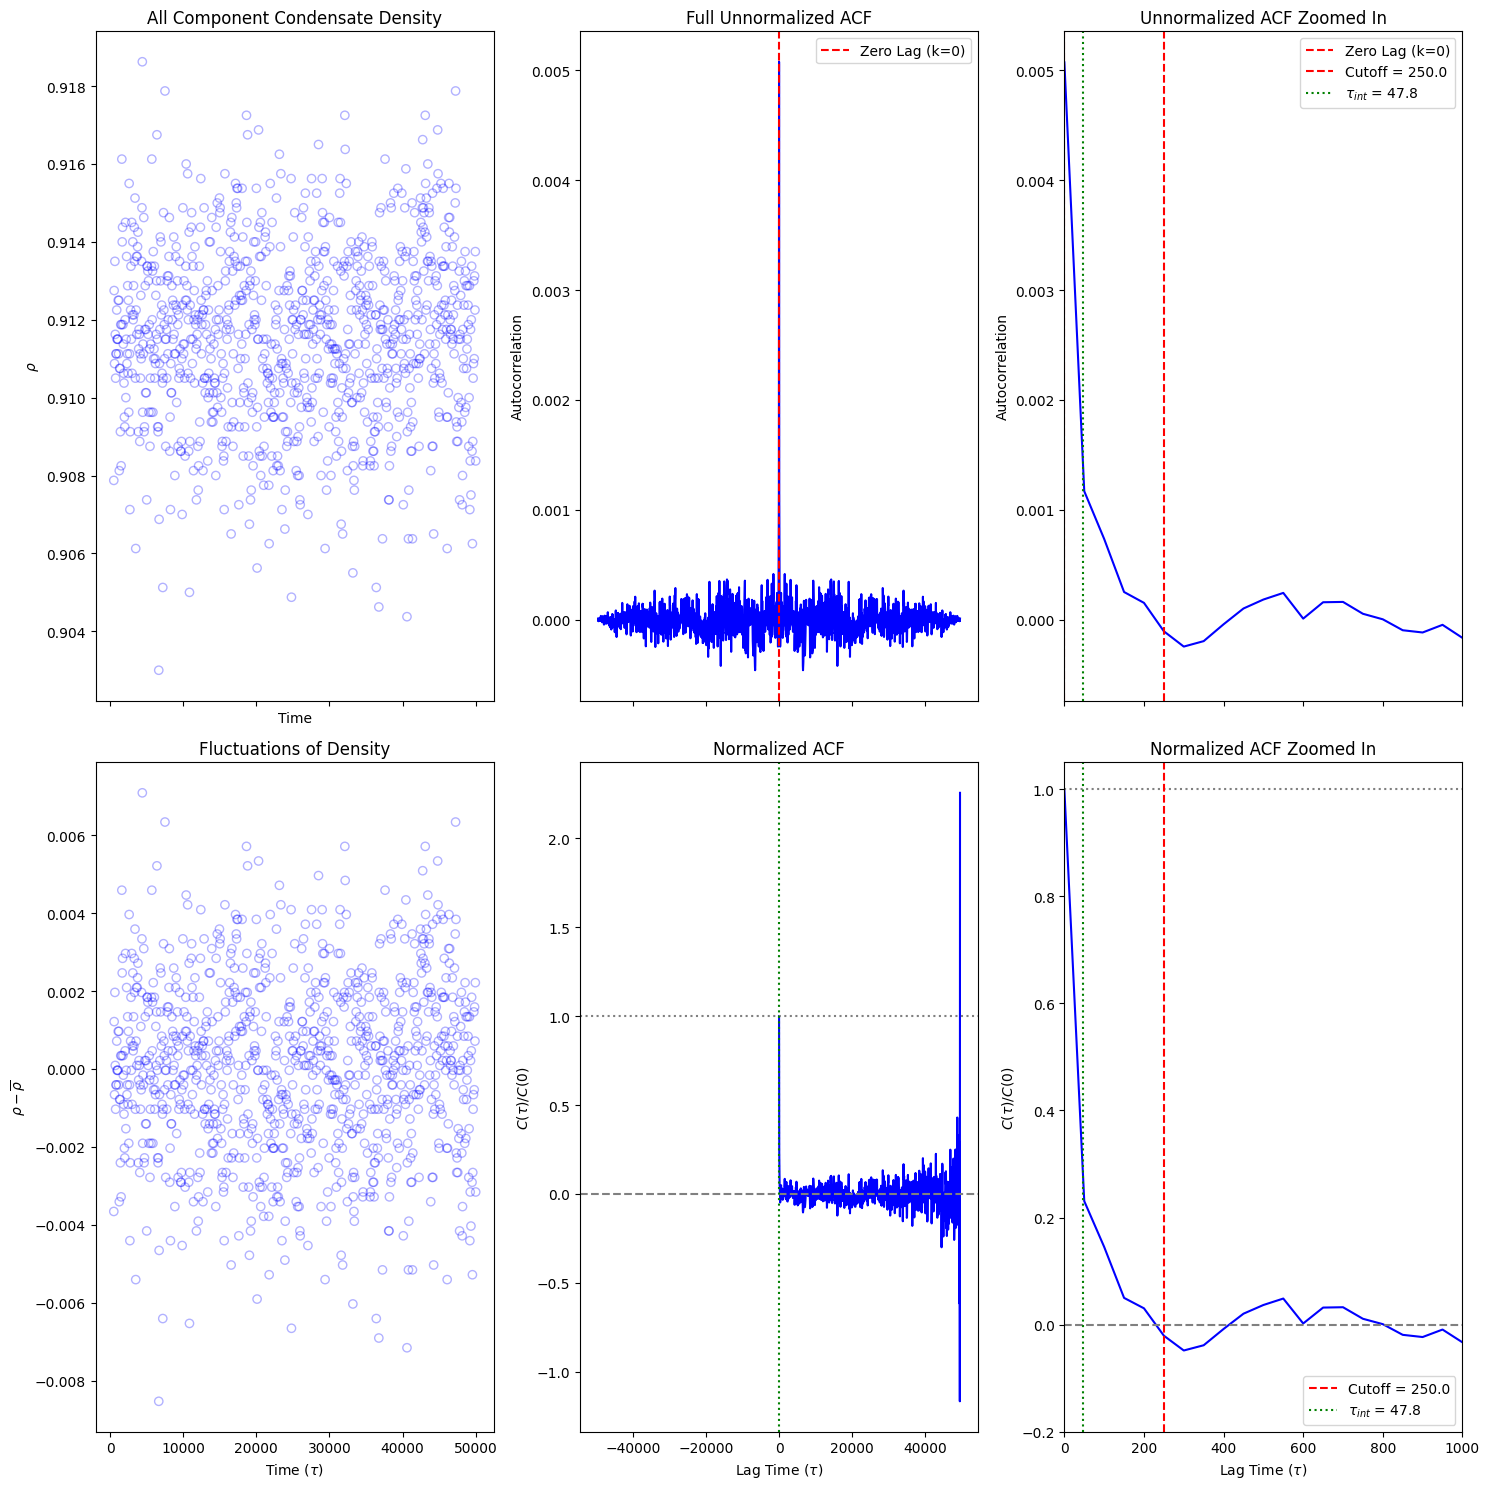

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(15, 15), sharex='col')

# Original Data
time, rho = np.asarray(time), np.asarray(rho_all_dense)
ax[0, 0].scatter(time, rho, alpha=0.3, facecolors='None', edgecolors='Blue')
ax[0, 0].set_xlabel('Time')
ax[0, 0].set_ylabel(r'$\rho$')
ax[0, 0].set_title('All Component Condensate Density')

# Fluctuations
fluctuations = rho - np.mean(rho)
ax[1, 0].scatter(time, fluctuations, alpha=0.3, facecolors='None', edgecolors='Blue')
ax[1, 0].set_xlabel(r'Time ($\tau$)')
ax[1, 0].set_ylabel(r'$\rho - \overline{\rho}$')
ax[1, 0].set_title('Fluctuations of Density')

# ACF and cutoff
N = len(fluctuations)
dt = np.mean(np.diff(time))
acf_full = correlate(fluctuations, fluctuations, mode="full", method="fft")
# Signed lag indices: -(N-1), ..., 0, ..., N-1
lag_indices_full = np.arange(-(N-1), N)
lag_times_full = lag_indices_full * dt
ax[0, 1].plot(lag_times_full, acf_full, color='Blue')
ax[0, 1].axvline(0, linestyle='--', color='Red', label='Zero Lag (k=0)')
ax[0, 1].set_ylabel('Autocorrelation')
ax[0, 1].set_title('Full Unnormalized ACF')
ax[0, 1].legend()

# Normalized ACF and cutoff
cutoff = N - 1
acf = acf_full[cutoff:]
lag_indices = np.arange(N)
lag_times = lag_indices * dt
# Unbiased normalization by overlapping sample count
normalization = N - lag_indices
acf = acf / normalization
# Normalize so ACF(0) = 1
acf = acf / acf[0]
ax[1, 1].plot(lag_times, acf, color='Blue')
ax[1, 1].axhline(0, linestyle='--', color='Gray')
ax[1, 1].axhline(1, linestyle=':', color='Gray')
ax[1, 1].set_xlabel(r'Lag Time ($\tau$)')
ax[1, 1].set_ylabel(r'$C(\tau)/C(0)$')
ax[1, 1].set_title('Normalized ACF')

# Finding Integrated Autocorrelation Time
nonpositive = np.where(acf <= 0)[0]
if len(nonpositive) > 0:
    stop = nonpositive[0]
else:
    stop = len(acf)
dt = lag_times[1] - lag_times[0]
tau_cutoff = lag_times[stop] if stop < N else lag_times[-1]
tau_int = dt * (0.5 + np.sum(acf[1:stop]))
ax[1, 1].axvline(tau_int, color='Green', linestyle=':', label=rf'$\tau_{{int}}$ = {tau_int:.2f}')

# Zoomed In
ax[0, 2].plot(lag_times_full, acf_full, color='Blue')
ax[0, 2].axvline(0, linestyle='--', color='Red', label='Zero Lag (k=0)')
ax[0, 2].set_ylabel('Autocorrelation')
ax[0, 2].set_title('Unnormalized ACF Zoomed In')
ax[0, 2].axvline(tau_cutoff, color='Red', linestyle='--', label=rf'Cutoff = {tau_cutoff:.1f}')
ax[0, 2].axvline(tau_int, color='Green', linestyle=':', label=rf'$\tau_{{int}}$ = {tau_int:.1f}')
ax[0, 2].legend()
ax[0, 2].set_xlim(0, 1000)

ax[1, 2].plot(lag_times, acf, color='Blue')
ax[1, 2].axhline(0, linestyle='--', color='Gray')
ax[1, 2].axhline(1, linestyle=':', color='Gray')
ax[1, 2].set_xlabel(r'Lag Time ($\tau$)')
ax[1, 2].set_ylabel(r'$C(\tau)/C(0)$')
ax[1, 2].set_title('Normalized ACF Zoomed In')
ax[1, 2].axvline(tau_cutoff, color='Red', linestyle='--', label=rf'Cutoff = {tau_cutoff:.1f}')
ax[1, 2].axvline(tau_int, color='Green', linestyle=':', label=rf'$\tau_{{int}}$ = {tau_int:.1f}')
ax[1, 2].legend()
ax[1, 2].set_xlim(0, 1000)
ax[1, 2].set_ylim(-0.2, 1.05)

plt.tight_layout()
plt.show()

# print(np.max(lag_times))
# print(f'Tau Int in LJ units = {tau_int}')
# print(f'Tau Int in Frames ~ {tau_int / dt}')

## Statistic Parameter Searches
Finding the decay in SEM at different block sizes to determine an appropriate sampling.

### Terms
B = block size (number of frames in each block)
SEM(B) = error of density between each block (sigma_blocks / sqrt(N_blocks))

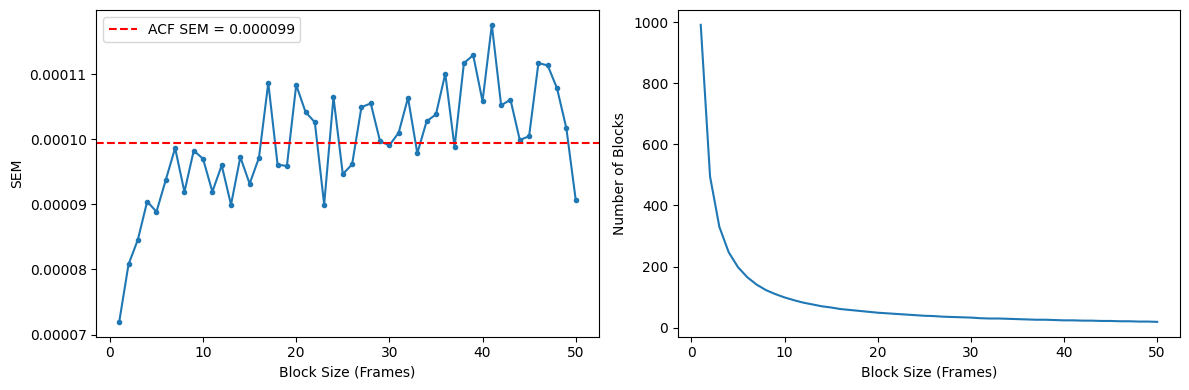

In [4]:
# General Block SEM Calculation
def calc_block_SEM(data, block_size):
    data = np.asarray(data)
    N_samples = len(data)
    N_blocks = N_samples // block_size
    
    if N_blocks < 2:
        return np.nan
        
    block_means = []
    for i in range(1, N_blocks+1):
        start = block_size * (i-1)
        end = block_size * i
        block_data = data[start:end]
        block_mean = np.mean(block_data)
        block_means.append(block_mean)
    SEM = np.std(block_means, ddof=1) / np.sqrt(N_blocks)
    return SEM

# ACF-Based SEM Calculation
def calc_Neff_ACFSEM(data, N, dt, tau_int):
    data = np.asarray(data)
    N_eff = N * dt / (2 * tau_int)
    SEM_ACF = np.std(data, ddof=1) / np.sqrt(N_eff)
    return N_eff, SEM_ACF

N_eff, ACF_SEM = calc_Neff_ACFSEM(rho, N, dt, tau_int)

# Plot different block sizes SEM against ACF SEM
block_sizes = np.arange(3, 200, 1)
block_SEMs = [calc_block_SEM(rho, size) for size in block_sizes]

block_sizes = np.arange(1, 51)

block_SEMs = [calc_block_SEM(rho, B) for B in block_sizes]
n_blocks = [len(rho) // B for B in block_sizes]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(block_sizes, block_SEMs, marker='o', markersize=3)
ax[0].axhline(ACF_SEM, color='red', linestyle='--',
              label=f'ACF SEM = {ACF_SEM:.6f}')
ax[0].set_xlabel('Block Size (Frames)')
ax[0].set_ylabel('SEM')
ax[0].legend()

ax[1].plot(block_sizes, n_blocks)
ax[1].set_xlabel('Block Size (Frames)')
ax[1].set_ylabel('Number of Blocks')

plt.tight_layout()
plt.show()